# Vehicle Fuel Efficiency: Endterm Report

**Team:** Aktore, Khamza, Askhat. **Question:** can vehicle specifications predict EPA combined US MPG? This is regression, with MAE in MPG as the primary metric; RMSE in MPG and R-squared are secondary. Higher MPG means greater efficiency.

We continue the midterm regression workflow and add K-Means, PCA, a feedforward ANN, refined supervised tuning and unified error analysis. This report audits training data and displays frozen experiment results. It does not retrain models or generate new test predictions. The numbered notebooks provide method-specific walkthroughs.

In [2]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display
from vehicle_efficiency.neural_network import load_training_data
from vehicle_efficiency.preprocessing import missing_summary, split_xy, add_features

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'pyproject.toml').exists())
results = root / 'reports/results/endterm'
figures = root / 'reports/figures/endterm'
train, _, manifest = load_training_data()
comparison_val = pd.read_csv(results / 'model_comparison_validation.csv')
ann = json.loads((results / 'ann_metrics.json').read_text())
display(pd.Series(manifest['split_sizes'], name='Rows').to_frame())
print('Raw SHA-256:', manifest['raw_sha256'])

,Rows
train,9816
val,2080
test,2079


Raw SHA-256: b1ff0e3071c46cdc1c99e0015878b98a01851462d7e447237ce2fc1294ccf303


## Dataset, cleaning and evaluation design

Source: [U.S. EPA / DOE FuelEconomy.gov](https://www.fueleconomy.gov/feg/ws/index.shtml), a real public dataset. The scoped snapshot has 13,975 rows and 14 columns, including identifiers and target. We retain model years 2015+ and exclude EV, fuel-cell, plug-in-hybrid and specified non-comparable fuel entries. Ordinary non-plug-in hybrids remain. Full schema, source terms and cleaning are in `data/README.md`.

The shared loader normalizes automatic/manual transmission and derives hybrid/turbo/supercharged flags. The audit below uses training rows only. Plausible rare engine configurations are retained rather than automatically deleted.

Seed-42 duplicate-grouped partitions contain 9,816 train, 2,080 validation and 2,079 previously used holdout rows. Exact duplicate records stay together; related make/model variants can still cross partitions. Preprocessing fits on train only, within each CV training fold where applicable. The holdout was used in midterm and is not a new independent endterm test.

In [3]:
display(missing_summary(train))
display(train[['mpg', 'cylinders', 'displacement', 'model_year']].describe().round(3))
print('Repeated vehicle records in train (excluding row_id):',
      train.drop(columns='row_id').duplicated().sum())

,missing,percent
model_year,0,0.0
cylinders,0,0.0
displacement,0,0.0
hybrid,0,0.0
turbo,0,0.0
supercharged,0,0.0
drive,0,0.0
transmission,0,0.0
vehicle_class,0,0.0
fuel_type,0,0.0


,mpg,cylinders,displacement,model_year
count,9816.000,9816.000,9816.000,9816.000
mean,23.208,5.567,3.113,2020.302
std,6.235,1.842,1.313,3.470
min,9.000,3.000,0.900,2015.000
25%,19.000,4.000,2.000,2017.000
50%,22.000,6.000,3.000,2020.000
75%,26.000,6.000,3.600,2023.000
max,59.000,16.000,8.400,2027.000


Repeated vehicle records in train (excluding row_id): 325


## Training-only EDA

These four analyses are retained from the midterm as required context for the final workflow; they are not claimed as new endterm methods. `00_eda.ipynb` contains the plotting code and detailed interpretations.

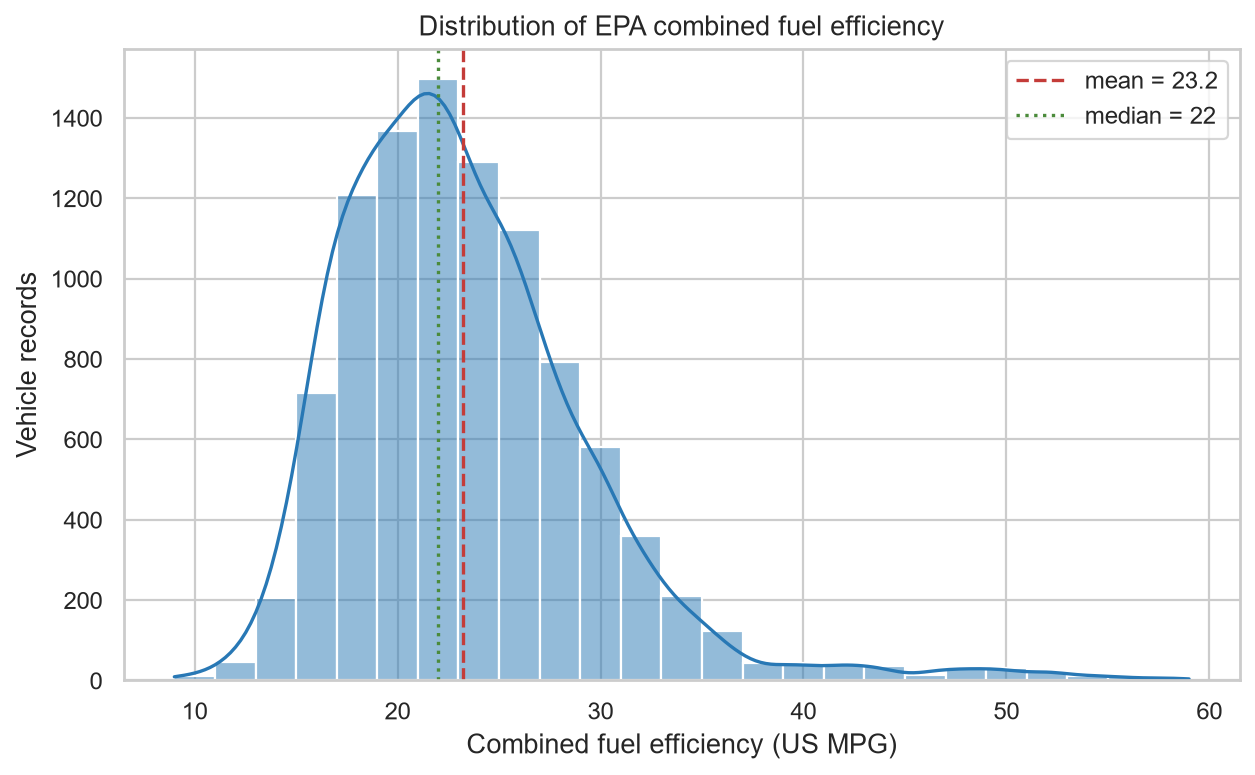

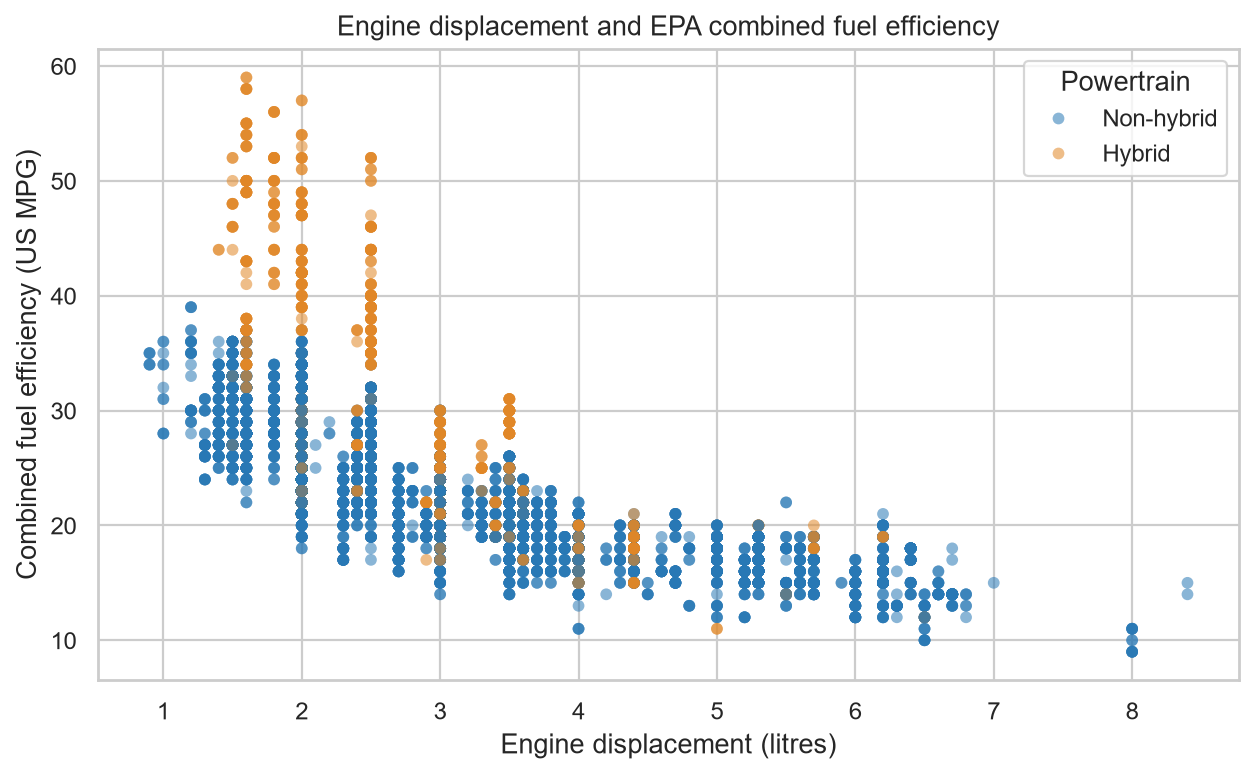

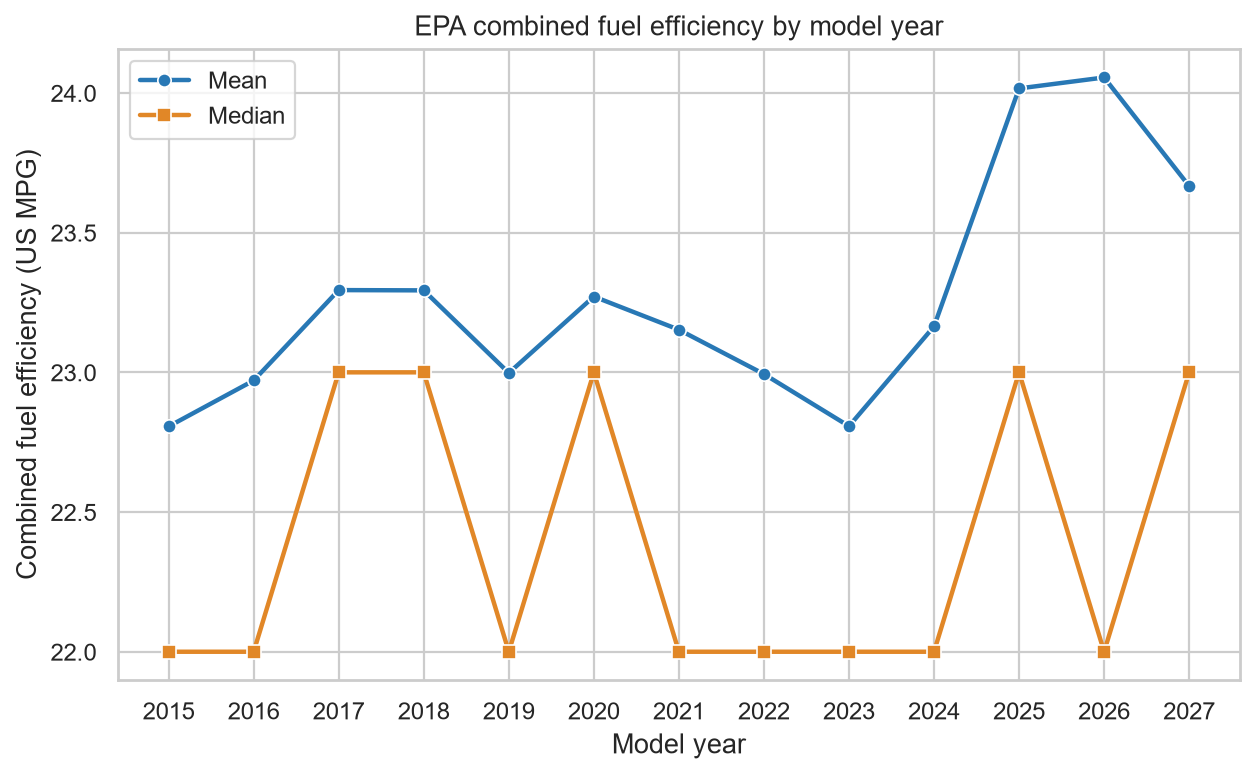

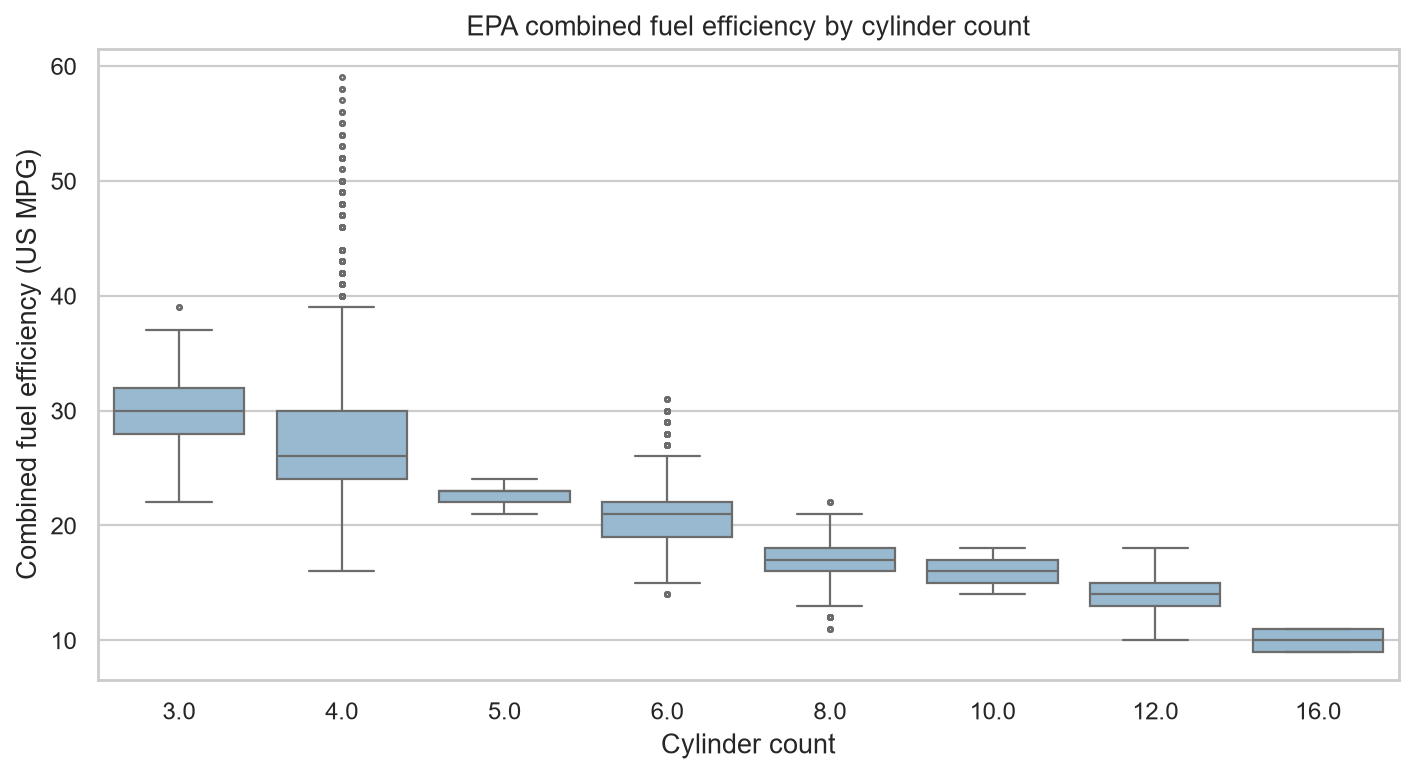

In [4]:
for name in ['eda_target_distribution.png', 'eda_displacement_vs_mpg.png',
             'eda_mpg_by_model_year.png', 'eda_mpg_by_cylinders.png']:
    display(Image(filename=str(figures / name)))

MPG is concentrated around 19-26 with a thinner high-efficiency tail. Displacement has a negative training correlation with MPG (about -0.705), with considerable variation at a given engine size. Cylinder count is similarly ordered: four-cylinder vehicles average about 27.6 MPG, six-cylinder about 21.0 and eight-cylinder about 17.1. Year alone has a weak linear association (about 0.034). Rare cylinder counts and small year groups need caution. These are descriptive associations, not causal estimates.

## Features and preprocessing

Predictors are model year, cylinders, displacement, technology flags, drive, transmission, vehicle class and fuel type, plus the inherited `displacement_per_cylinder` feature. MPG, raw `comb08`, row ID, make and model are excluded from predictors. Make/model remain available for identification and error analysis.

Numeric features use median imputation; categories use most-frequent imputation and one-hot encoding with unknown categories ignored. Scaling is used where needed, including KNN and ANN. All fitted statistics/categories come from training data; ANN target standardization also fits only on train. The tree does not require numeric scaling. Implementations: `data.py`, `preprocessing.py`, `models.py`.

In [5]:
X_train, y_train = split_xy(train)
assert not {'mpg', 'comb08', 'row_id', 'make', 'model'} & set(X_train.columns)
display(add_features(X_train).head())

,model_year,cylinders,displacement,hybrid,turbo,supercharged,drive,transmission,vehicle_class,fuel_type,displacement_per_cylinder
1,2015,5.0,2.5,0,1,0,All-Wheel Drive,Automatic,Compact Cars,Regular Gasoline,0.500000
2,2015,4.0,2.5,0,0,0,Front-Wheel Drive,Automatic,Midsize Cars,Regular Gasoline,0.625000
4,2015,4.0,2.5,0,0,0,Front-Wheel Drive,Manual,Midsize Cars,Regular Gasoline,0.625000
5,2015,6.0,3.8,0,0,0,Rear-Wheel Drive,Automatic,Large Cars,Regular Gasoline,0.633333
6,2015,8.0,5.0,0,0,0,Rear-Wheel Drive,Automatic,Large Cars,Premium Gasoline,0.625000


## Supervised models and tuning

We retain the mean baseline, Linear Regression, Decision Tree and KNN, and include Ridge. Classical hyperparameters use five-fold duplicate-grouped CV within train, with preprocessing fitted inside each fold. The endterm grids refine tree depth/leaf sizes, KNN neighbors/distance/weights and Ridge alpha. Final model selection uses validation MAE. `endterm_compare.py` implements the comparison; the completed final holdout table prevents accidental new selection after seeing holdout scores.

In [6]:
tuning = pd.read_csv(results / 'supervised_tuning.csv')
display(tuning.sort_values(['model', 'cv_mae']).groupby('model').head(3))
display(comparison_val.round(4))

,model,parameters,cv_mae,cv_std,cv_train_mae
0,Baseline (mean),{},4.635465,0.066801,4.634880
13,Decision Tree,"{""model__max_depth"": null, ""model__min_samples...",1.089671,0.016369,0.674257
12,Decision Tree,"{""model__max_depth"": null, ""model__min_samples...",1.090478,0.023657,0.538376
9,Decision Tree,"{""model__max_depth"": 16, ""model__min_samples_l...",1.090761,0.024186,0.688527
19,KNN,"{""model__n_neighbors"": 3, ""model__p"": 1, ""mode...",1.111760,0.032896,0.780732
24,KNN,"{""model__n_neighbors"": 4, ""model__p"": 1, ""mode...",1.116460,0.032136,0.547353
20,KNN,"{""model__n_neighbors"": 3, ""model__p"": 1, ""mode...",1.117026,0.032997,0.558646
1,Linear Regression,{},1.985638,0.036415,1.975658
4,Ridge,"{""model__alpha"": 1.0}",1.985554,0.036748,1.975883
3,Ridge,"{""model__alpha"": 0.1}",1.985567,0.036435,1.975694


,model,selected_parameters,train_mae,validation_mae,validation_rmse,validation_r2
0,Decision Tree,"{""model__max_depth"": null, ""model__min_samples...",0.6856,1.0510,1.6365,0.9303
1,Feedforward ANN,"{""hidden_sizes"": [64, 32], ""learning_rate"": 0....",0.9460,1.0827,1.5230,0.9396
2,KNN,"{""model__n_neighbors"": 3, ""model__p"": 1, ""mode...",0.7789,1.0894,1.6722,0.9272
3,Linear Regression,{},1.9767,2.0186,2.7779,0.7990
4,Ridge,"{""model__alpha"": 1.0}",1.9770,2.0205,2.7784,0.7990
5,Baseline (mean),{},4.6350,4.6618,6.1967,-0.0000


## K-Means engine profiles

K-Means uses cylinders and displacement with train-fitted median imputation and StandardScaler. MPG is not used to fit or select clusters. We compare k=2 through 8. Three clusters offer an interpretable partition and a sampled silhouette of 0.727; k=4 has higher silhouette (0.753) but creates a smaller group. Thus k=3 is an interpretation tradeoff, not the unique mathematical optimum. Silhouette uses a fixed 3,000-row sample.

,k,inertia,silhouette,min_cluster_size
0,2,6525.056177,0.662771,2058
1,3,2516.721516,0.727389,2058
2,4,1380.506535,0.753399,205
3,5,912.039102,0.752476,205
4,6,691.263594,0.700860,205
5,7,526.679265,0.715710,205
6,8,403.978054,0.724120,205


,cluster,n,cylinders_mean,displacement_mean_l,mpg_mean,mpg_median,center_cylinders,center_displacement_l
0,0,4581,3.967,2.039,27.639,26.0,3.967,2.039
1,1,3177,6.000,3.298,21.020,21.0,6.000,3.298
2,2,2058,8.460,5.217,16.721,17.0,8.460,5.217


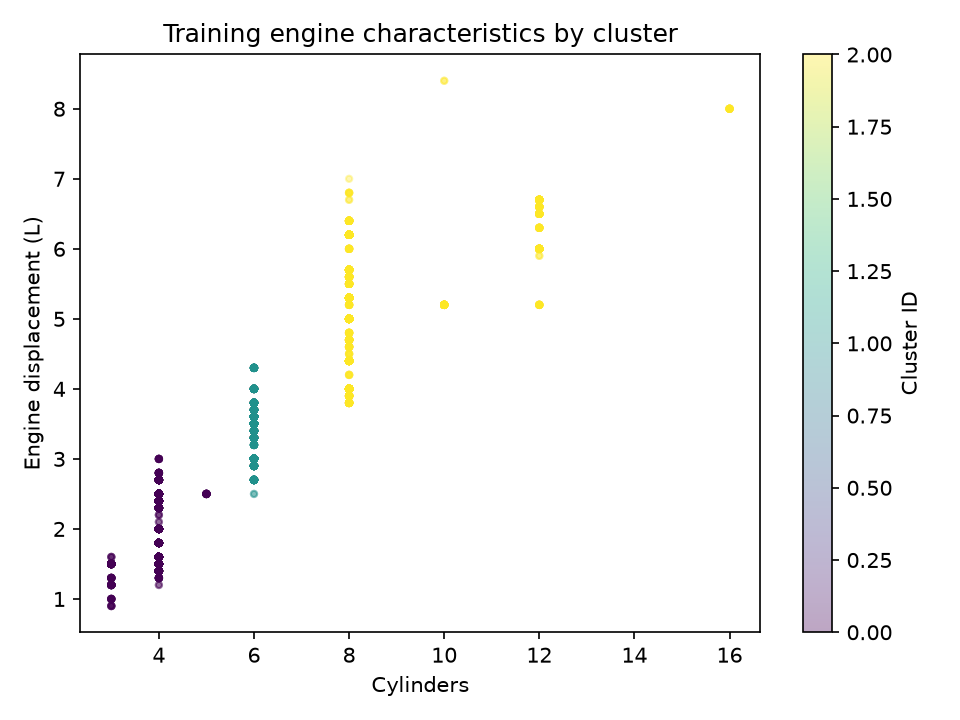

In [7]:
display(pd.read_csv(results / 'clustering_search.csv'))
display(pd.read_csv(results / 'clustering_profiles.csv').round(3))
display(Image(filename=str(figures / 'clustering_scatter.png')))

Centers are near 4 cylinders/2.04 L, 6/3.30 L and 8.46/5.22 L; their mean MPG values are approximately 27.64, 21.02 and 16.72. Cluster IDs are arbitrary labels, not quality ranks. MPG summaries are computed after clustering and are descriptive. This engine analysis complements, rather than replaces, MPG regression. Implementation: `clustering.py`; walkthrough: `01_clustering.ipynb`.

## PCA and cluster overlay

Train-only PCA uses the same two engine inputs after median imputation and standardization. Keeping PC1 reduces two features to one while retaining 96.06% of variance. The two-component scatter retains 100% and is a rotation, not a 2-to-2 reduction. The overlay joins the saved K-Means assignments on identical unique training row IDs. PCA maximizes feature variance, not MPG accuracy, and does not prove natural clusters. Implementation: `dimensionality_reduction.py`; walkthrough: `02_pca.ipynb`.

,component,explained_variance_ratio,cumulative_explained_variance
0,PC1,0.960637,0.960637
1,PC2,0.039363,1.000000


,feature,PC1,PC2
0,cylinders,0.707107,-0.707107
1,displacement,0.707107,0.707107


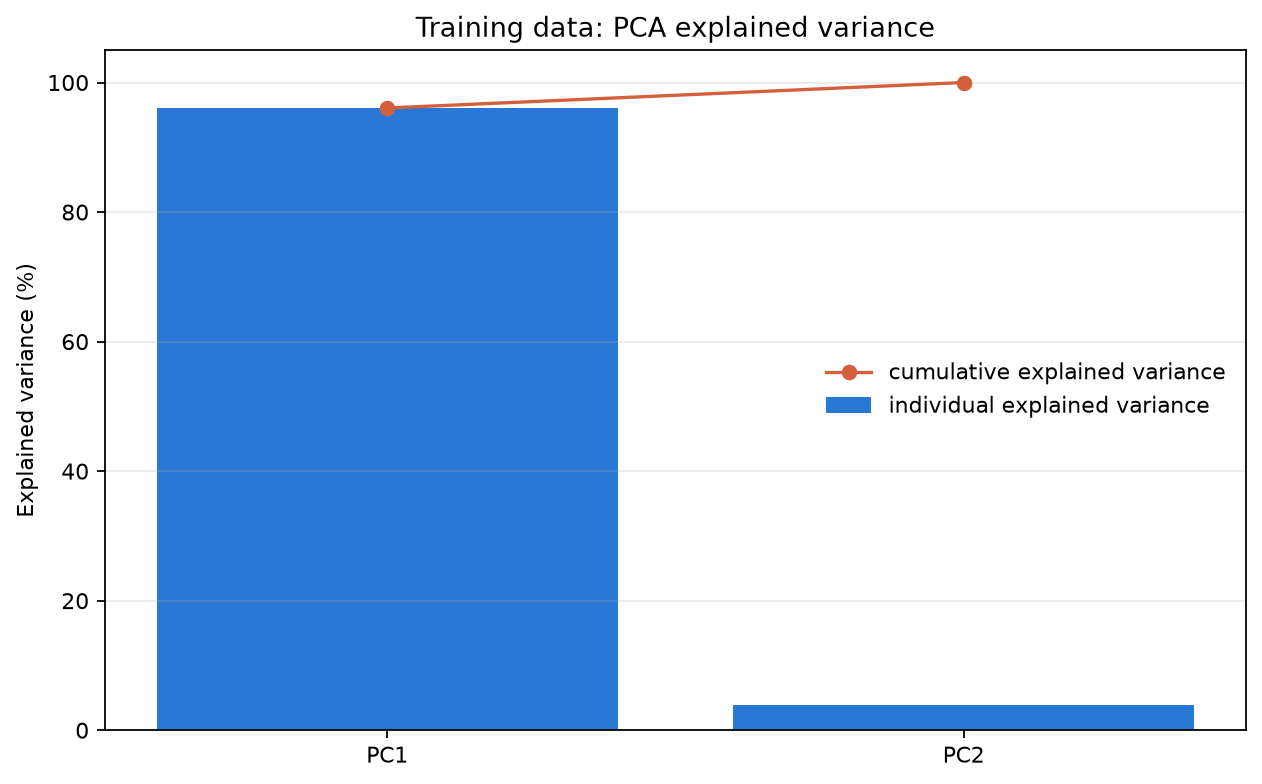

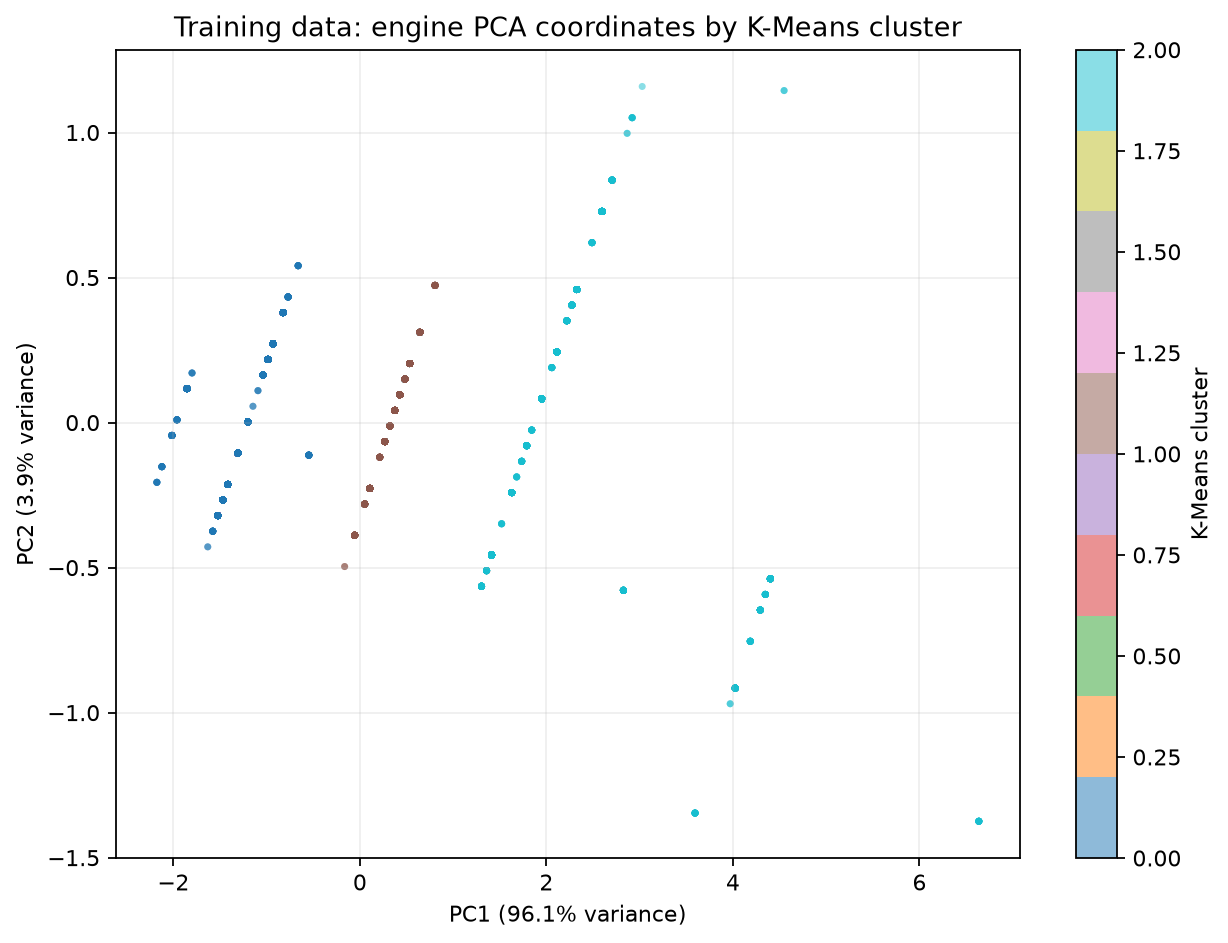

In [8]:
display(pd.read_csv(results / 'pca_variance.csv'))
display(pd.read_csv(results / 'pca_loadings.csv'))
display(Image(filename=str(figures / 'pca_explained_variance.png')))
display(Image(filename=str(figures / 'pca_clusters_train.png')))

## Feedforward ANN

For these tabular data, the feedforward ANN is the required deep-learning model; there is no image/text modality requiring CNN or NLP. The network has 40 encoded inputs, ReLU hidden layers of 64 and 32 units, and one unrestricted linear output. It predicts a train-standardized target, inverse-transformed back to MPG.

The predeclared grid compares hidden sizes (32,) and (64,32) with learning rates 0.001 and 0.0003. Training uses CPU, seed 42, Adam, MSE, batch size 64, a 200-epoch cap and patience 20. Checkpoints minimize validation MSE; restored candidates are selected by validation MAE. The winning run restores epoch 113 after stopping at 133. Validation is reused for selection, so its score is selection-biased and ANN has no claimed grouped CV. Implementation: `neural_network.py`; full training walkthrough: `03_ann.ipynb`.

,candidate,hidden_sizes,learning_rate,best_epoch,epochs_run,stopped_early,train_mae,train_rmse,train_r2,val_mae,val_rmse,val_r2,selected
0,h64-32_lr0.001,"[64, 32]",0.0010,113,133,True,0.9460,1.3111,0.9558,1.0827,1.5230,0.9396,True
1,h64-32_lr0.0003,"[64, 32]",0.0003,195,200,False,0.9723,1.3411,0.9537,1.1090,1.5580,0.9368,False
2,h32_lr0.001,[32],0.0010,95,115,True,1.1345,1.5254,0.9401,1.2067,1.6567,0.9285,False
3,h32_lr0.0003,[32],0.0003,200,200,False,1.1591,1.5619,0.9372,1.2409,1.6906,0.9256,False


,mae,rmse,r2
Train,0.9460,1.3111,0.9558
Validation,1.0827,1.5230,0.9396


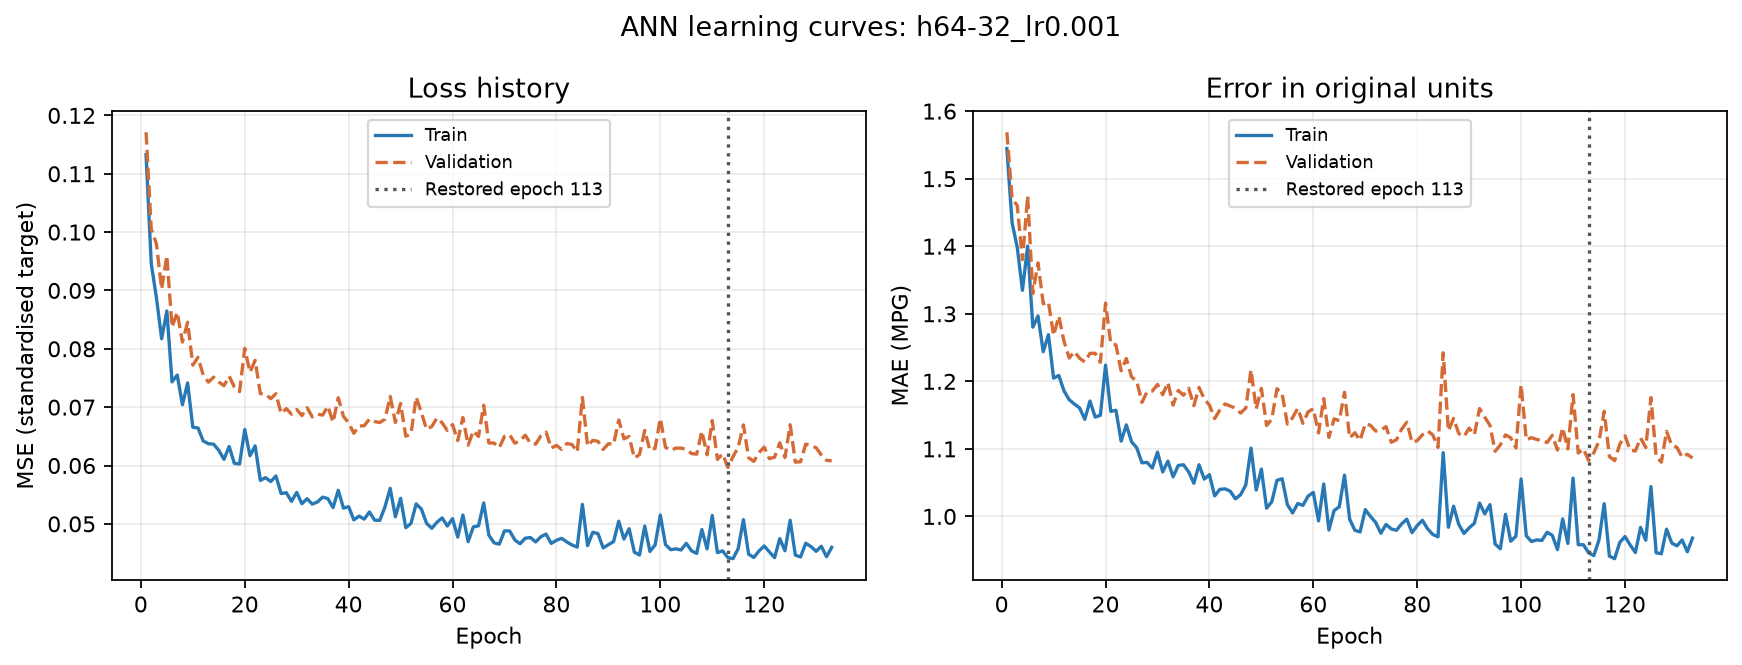

In [9]:
display(pd.read_csv(results / 'ann_search.csv').round(4))
display(pd.DataFrame({'Train': ann['train'], 'Validation': ann['validation']}).T.round(4))
display(Image(filename=str(figures / 'ann_learning_curves.png')))

The selected run has train MAE 0.946 and validation MAE 1.083 MPG, a gap of about 0.137. Loss falls and then fluctuates around a plateau. Restoring the best-loss checkpoint avoids keeping the final slightly worse state; no separate ablation proves a causal early-stopping benefit. The slower learning-rate candidates reached the epoch cap, so their ranking could depend on training budget.

## Final comparison and error analysis

Decision Tree wins the declared primary validation-MAE rule: 1.051 MPG versus ANN 1.083. ANN has lower RMSE (1.523 versus 1.636) and higher R-squared (0.940 versus 0.930); this does not change the selection metric. A neural network is not guaranteed to outperform a tree on tabular data. Different tuning procedures and one snapshot/seed limit strong performance claims.

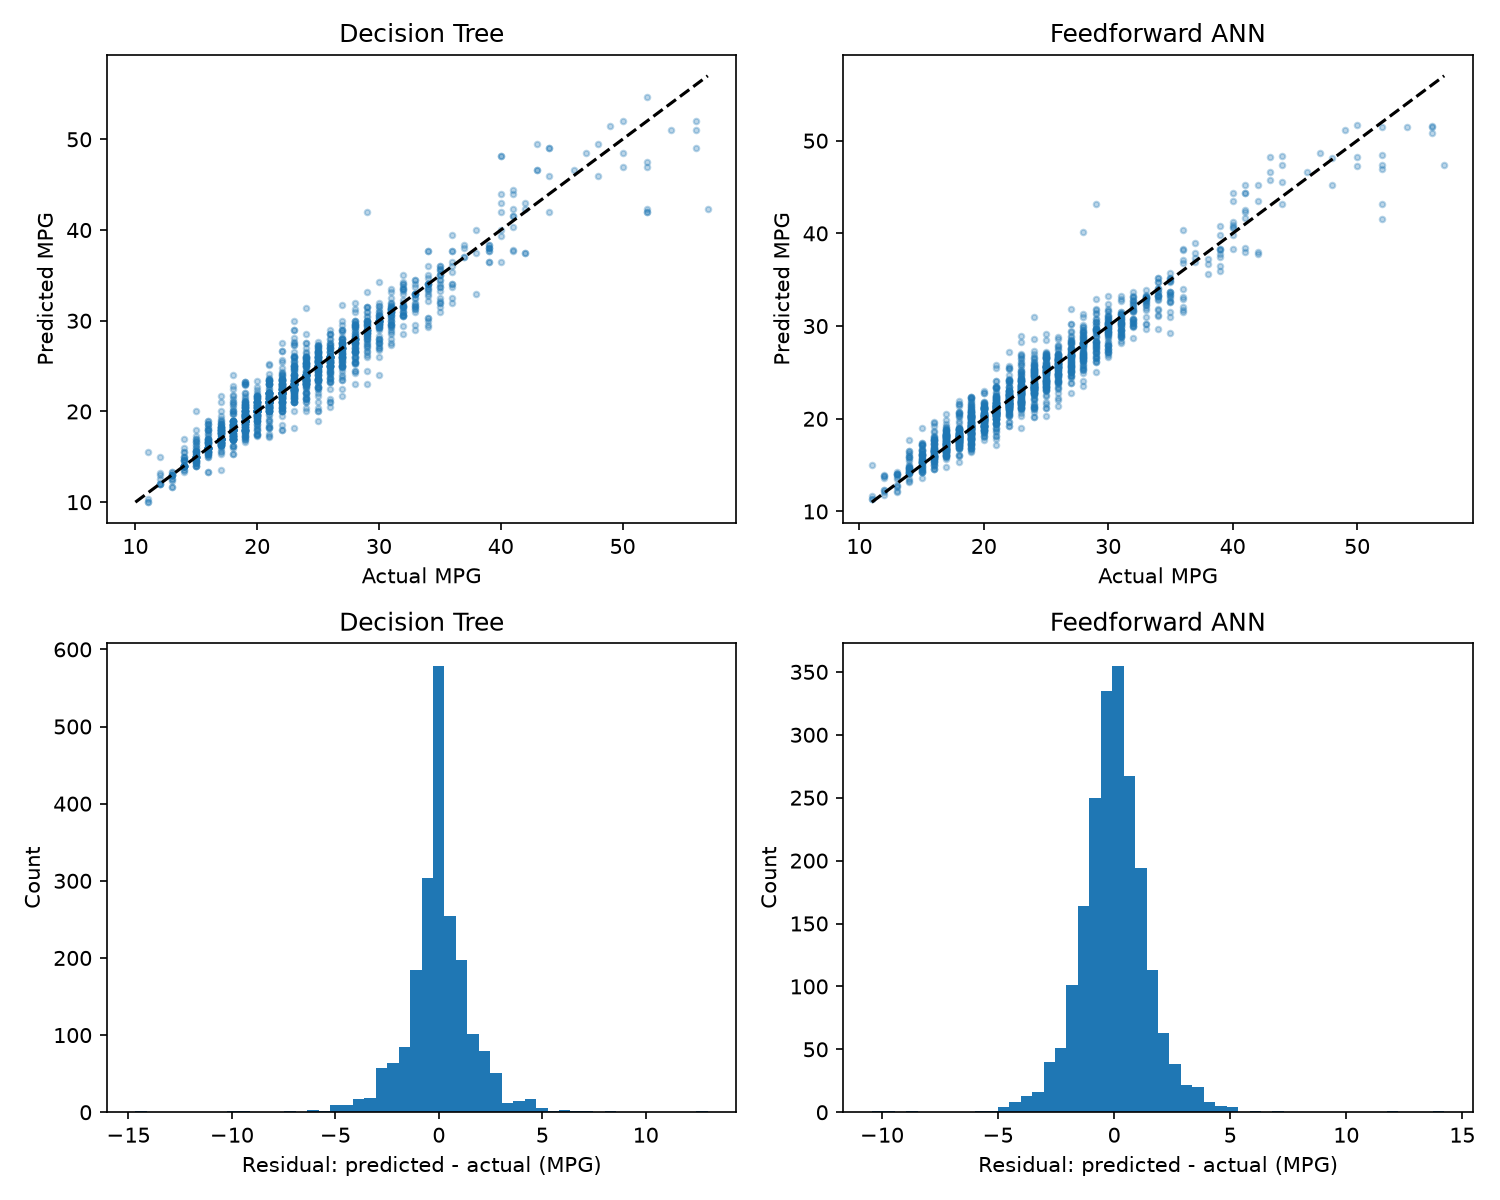

,model,group_type,group,n,mae,mean_error
0,Decision Tree,hybrid,0,1839,0.949,-0.007
1,Decision Tree,hybrid,1,241,1.827,0.068
24,Feedforward ANN,hybrid,0,1839,1.006,-0.027
25,Feedforward ANN,hybrid,1,241,1.667,0.176


,model_predictor,row_id,y_true,y_pred,make,model_vehicle,model_year,vehicle_class,hybrid,cylinders,displacement,error,absolute_error
0,Decision Tree,39963,57,42.333333,Toyota,Prius,2023,Midsize Cars,1,4.0,2.0,-14.666667,14.666667
1,Decision Tree,33230,29,42.000000,Buick,LaCrosse eAssist,2019,Midsize Cars,1,4.0,2.5,13.000000,13.000000
2,Decision Tree,31786,52,42.000000,Toyota,Camry Hybrid LE,2018,Midsize Cars,1,4.0,2.5,-10.000000,10.000000
3,Decision Tree,33765,52,42.000000,Toyota,Camry Hybrid LE,2019,Midsize Cars,1,4.0,2.5,-10.000000,10.000000
4,Decision Tree,39967,52,42.333333,Toyota,Prius XLE/LTD,2023,Midsize Cars,1,4.0,2.0,-9.666667,9.666667
5,Decision Tree,43268,40,48.200000,Honda,CR-V FWD,2026,Midsize Station Wagons,1,4.0,2.0,8.200000,8.200000
6,Decision Tree,44821,40,48.200000,Honda,CR-V FWD,2027,Midsize Station Wagons,1,4.0,2.0,8.200000,8.200000
7,Decision Tree,34956,24,31.400000,Ford,Fusion FWD,2020,Midsize Cars,0,4.0,2.5,7.400000,7.400000
8,Decision Tree,32693,56,49.000000,Toyota,Prius Eco,2018,Midsize Cars,1,4.0,1.8,-7.000000,7.000000
9,Decision Tree,42289,23,30.000000,Toyota,Tacoma Hybrid 4WD,2024,Standard Pickup Trucks 4WD,1,4.0,2.4,7.000000,7.000000


In [10]:
display(Image(filename=str(figures / 'evaluation_validation.png')))
errors = pd.read_csv(results / 'error_by_group_validation.csv')
display(errors[errors.group_type == 'hybrid'].round(3))
display(pd.read_csv(results / 'largest_errors_validation.csv').head(10))

Residuals are predicted minus actual MPG. On validation, the tree's MAE is 1.827 MPG for 241 hybrids versus 0.949 for 1,839 non-hybrids. These differences suggest follow-up questions rather than proving a cause; hybrid-system detail is missing. Interpret vehicle-class errors alongside group size. Full tables and diagnostics are in `04_evaluation.ipynb`.

## Previously used holdout

The following is the recorded final comparison after configurations were fixed. This 2,079-row holdout was already evaluated in midterm, so it is not a new independent test. The notebook only reads the saved table, with no new predictions, model selection or tuning.

In [11]:
display(pd.read_csv(results / 'model_comparison_test.csv').round(4))

,model,mae,rmse,r2
0,Baseline (mean),4.5867,6.2185,-0.0003
1,Linear Regression,1.9981,2.7820,0.7998
2,Ridge,1.9974,2.7816,0.7999
3,Decision Tree,1.0738,1.6639,0.9284
4,KNN,1.0707,1.6331,0.9310
5,Feedforward ANN,1.0780,1.4731,0.9439


## Conclusions, limitations and contributions

The endterm adds K-Means, PCA and ANN to the retained supervised workflow, refines classical tuning and compares all six models on shared validation rows. The tree remains the MAE winner; ANN has lower RMSE. One PCA component summarizes most variation in the two selected engine features. Clusters describe engine groups, not causal MPG effects.

The selected source lacks weight, horsepower, aerodynamics, complete hybrid-system detail and real-world driving conditions. EPA lab ratings are not guaranteed driving fuel use or certified predictions. Results exclude pre-2015 and filtered powertrains. Related variants across splits, one snapshot/seed, validation selection and prior holdout use limit generalization. Small group comparisons need caution.

No dataset expansion is needed just to differ from midterm. Future work could predeclare make/model-grouped or temporal evaluation and separately integrate verified weight/horsepower data; it would require fresh evaluation, not a new claim from the current frozen table.

**Aktore:** PCA and final report integration (`2489abc`, `31097f4`, `c36ca09`). **Khamza:** ANN and reproducibility protocol (`eba318f`, `a0bf7a9`). **Askhat:** K-Means, classical refinement, comparison and error analysis (`316c517`, `34fed77`, `47b4919`, `b455bad`). Exact environment and launch commands are in README and `requirements-endterm.txt`.